# Rabbits and foxes, by kinetic Monte Carlo

**CHME 5137, Lecture 10, Tuesday October 13, 2026.** Started in class, finished for
homework.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's KMC question of
earlier years, and checked by Prof. West. The problem is from Chapter 1 of H. Scott
Fogler's "Essentials of Chemical Reaction Engineering".*

---

Same farm, same rate constants: 400 rabbits and 200 foxes at the start, and

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

with $k_1 = 0.015$ day$^{-1}$, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$,
$k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$ and $k_4 = 0.04$ day$^{-1}$.

In the `solve_ivp` homework you found that the foxes fall to **under two** in each
trough. The ODEs don't mind: 1.6 foxes carry on and breed. Real foxes can't be
fractional, and two foxes can easily both die before they meet a rabbit. So now we
treat every rabbit and fox as an individual, and every birth and death as a random
event. That is **kinetic Monte Carlo** (KMC).

### The events

There are four events. Each has a rate, in events per day, which changes as the
populations change:

| Event | Rate | Effect |
|---|---|---|
| a rabbit is born | $k_1 R$ | $R \to R + 1$ |
| a rabbit is eaten | $k_2 R F$ | $R \to R - 1$ |
| a fox is born | $k_3 R F$ | $F \to F + 1$ |
| a fox dies | $k_4 F$ | $F \to F - 1$ |

The rates are easy to calculate, so we use the **rejection-free** algorithm, which you
worked out in class from
[Wikipedia's Kinetic Monte Carlo page](https://en.wikipedia.org/wiki/Kinetic_Monte_Carlo).
Writing it down in your own words is the first part of task 1.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at. **Commit the `.ipynb`
  and its paired `.py` together**: the `.py` is the one whose diffs you can read on
  GitHub. If saving the notebook doesn't update the `.py`, see *Setting up Jupytext* on
  Canvas.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Random numbers:** use a NumPy generator, `rng = np.random.default_rng(seed)`,
  not the legacy `np.random.*` functions. Give it a seed, so that Restart & Run All
  gives the same answers every time. Check what interval each function returns,
  and what its arguments mean, before you trust it.
- **Let bugs shout.** If a population goes negative or an event isn't one of the
  four, `raise` an error. Don't hide it with `max(0, F)`: that turns a bug you'd
  notice into a wrong answer you won't.

In [1]:
import time
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

R0, F0 = 400, 200  # rabbits and foxes at t = 0
t_end = 600  # days

The deterministic answer, for comparison. This is the `solve_ivp` homework's
solution, at a tight tolerance.

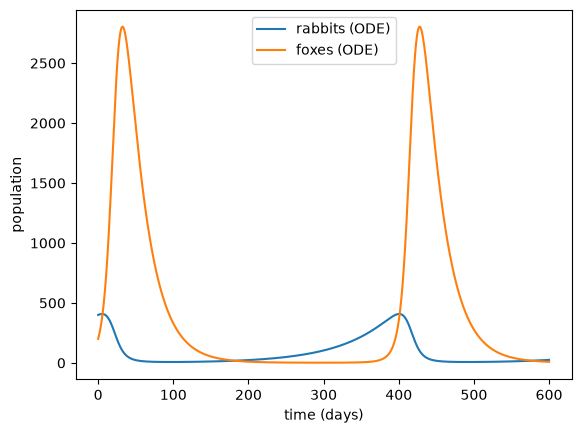

In [2]:
def dydt(t, y):
    R, F = y
    return [k1 * R - k2 * R * F, k3 * R * F - k4 * F]

ode = solve_ivp(dydt, (0, t_end), [R0, F0], rtol=1e-10, atol=1e-8, dense_output=True)
t_ode = np.linspace(0, t_end, 3001)
R_ode, F_ode = ode.sol(t_ode)

plt.plot(t_ode, R_ode, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, label="foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.show()

## 1. One trajectory

**(a) The algorithm, in your own words.** Before you write any code, write the
rejection-free algorithm as numbered steps, for rabbits and foxes: what each of
Wikipedia's symbols ($k$, $r_{ki}$, $R_{ki}$, $Q_k$, $u$, $u'$) becomes here, how the
next event is chosen, and how far the clock moves. Then work the **first step by
hand**, from 400 rabbits and 200 foxes, with $u = 0.5$ and $u' = 0.3$: which event
happens, and how many minutes pass?

*Answer:*

1(a). Rejection-free algorithm and first step
1. Set the clock to zero and the state $k=(R,F)=(400,200)$.
2. The four $r_{ki}$ are $(k_1R,k_2RF,k_3RF,k_4F)$. Their cumulative sums $R_{ki}$ define four intervals, with total rate $Q_k=\sum_i r_{ki}$. If $Q_k=0$, stop.
3. Draw independent uniforms $u,u'$ in $(0,1]$. Select the first cumulative rate at least $uQ_k$, then change the corresponding population by one.
4. Advance the clock by $\Delta t=-\ln(u')/Q_k$, using the total rate before the population changed. Record the new state and repeat until the clock exceeds 600 days.
Initially the rates are $(6,3.2,32,8)$ events/day, the cumulative rates are $(6,9.2,41.2,49.2)$, and $Q=49.2$. With $u=0.5$, $uQ=24.6$, so a fox is born, giving $(R,F)=(400,201)$. With $u'=0.3$,
$$\Delta t=\frac{-\ln(0.3)}{49.2}=0.02447099\text{ day}=\mathbf{35.2382\text{ minutes}}$$.


**(b) The function.** Write

```python
def kmc(R0, F0, t_end, rng):
    ...
    return times, rabbits, foxes   # three NumPy arrays, one entry per event
```

that runs your algorithm from $t = 0$ until the clock passes `t_end`. If the total
rate is ever zero, nothing more can happen, so stop there.

Run it once. How many events were there, and how long did it take? Plot rabbits and
foxes against time, on top of the ODE solution. (`plt.step(times, foxes, where="post")`
draws a population that jumps, rather than one that slopes.) Run it a few more times
with different seeds. How does a KMC trajectory differ from the ODE solution?

27,622 events; 0.0869 seconds


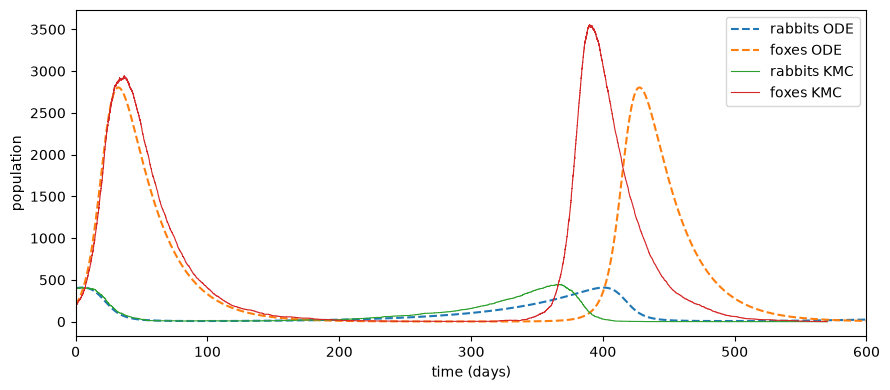

In [3]:
def kmc(R0, F0, t_end, rng):
    if (not isinstance(R0, (int, np.integer)) or
        not isinstance(F0, (int, np.integer)) or R0 < 0 or F0 < 0):
        raise ValueError('Initial populations must be nonnegative integers')
    if not np.isfinite(t_end) or t_end < 0:
        raise ValueError('t_end must be finite and nonnegative')
    t, R, F = 0.0, int(R0), int(F0)
    times, rabbits, foxes = [t], [R], [F]
    while t < t_end:
        a, b, c, d = k1*R, k2*R*F, k3*R*F, k4*F
        Q = a+b+c+d
        if Q == 0:
            break
        x = (1.0-rng.random())*Q
        dt = -math.log(1.0-rng.random())/Q
        if x <= a:
            R += 1
        elif x <= a+b:
            R -= 1
        elif x <= a+b+c:
            F += 1
        elif x <= Q:
            F -= 1
        else:
            raise RuntimeError('Invalid event')
        if R < 0 or F < 0:
            raise RuntimeError('Negative population')
        t += dt
        times.append(t); rabbits.append(R); foxes.append(F)
    return np.array(times), np.array(rabbits), np.array(foxes)

start = time.perf_counter()
times, rabbits, foxes = kmc(R0, F0, t_end, np.random.default_rng(5137))
single_elapsed = time.perf_counter()-start
print(f'{len(times)-1:,} events; {single_elapsed:.4f} seconds')
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(t_ode, R_ode, '--', label='rabbits ODE')
ax.plot(t_ode, F_ode, '--', label='foxes ODE')
ax.step(times, rabbits, where='post', lw=.8, label='rabbits KMC')
ax.step(times, foxes, where='post', lw=.8, label='foxes KMC')
ax.set(xlim=(0,600), xlabel='time (days)', ylabel='population')
ax.legend(); plt.tight_layout(); plt.show()

*Answer:*
The initial array entry is the initial condition; every later entry is an event. The final event may be after day 600, as requested. Values at day 600 must use the last event at or before day 600. KMC populations are integers and change in jumps. Their peaks and troughs vary in size and timing, and a species can go extinct; the deterministic solution remains smooth and positive.

## 2. Many trajectories, and where they end up

Plot the foxes from 20 trajectories on one graph (thin lines, `lw=0.5`), with the ODE
solution on top.

- What do the trajectories have in common, and where do they spread apart?
- What happens to a trajectory once the foxes reach zero? Once the rabbits reach
  zero? Why can't it ever recover?
- Where in the cycle do the foxes usually die out, and why there? (Your answer to
  task 5 of the `solve_ivp` homework is relevant.)

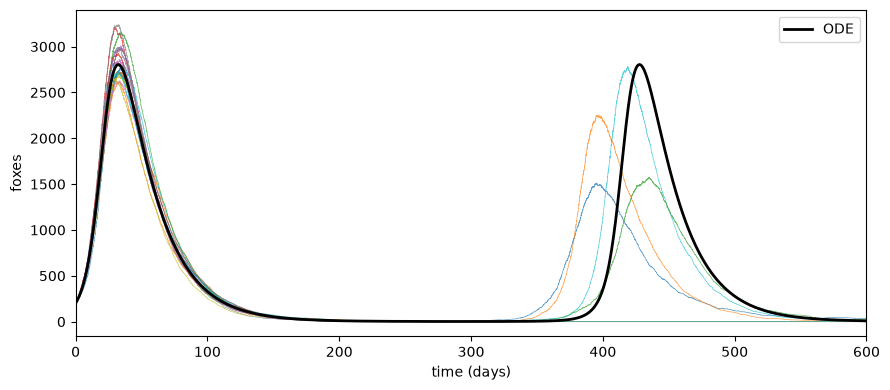

In [4]:
fig, ax = plt.subplots(figsize=(9,4))
twenty = []
for seed in range(20):
    ts, rs, fs = kmc(R0, F0, t_end, np.random.default_rng(1000+seed))
    twenty.append((ts, rs, fs))
    ax.step(ts, fs, where='post', lw=.5, alpha=.7)
ax.plot(t_ode, F_ode, 'k', lw=2, label='ODE')
ax.set(xlim=(0,600), xlabel='time (days)', ylabel='foxes')
ax.legend(); plt.tight_layout(); plt.show()

*Answer:*
The trajectories have a similar early fox boom and subsequent decline. They spread apart most strongly near the low-population trough and during recovery: chance deaths can eliminate the last few foxes, and surviving foxes restart growth at different times.
At $F=0$, both fox birth and fox death rates vanish permanently, and rabbits undergo pure birth. At $R=0$, both rabbit birth and consumption vanish permanently; fox births also stop, so the remaining foxes eventually die. Without immigration, neither extinct species can return.
Fox extinction tends to occur after the first boom, when rabbits are scarce and the fox population has declined to a few individuals. Fox per-capita growth is $k_3R-k_4$, which is negative below $R=100$. Even when rabbits recover, a small fox population can still disappear by chance before it establishes growth.

## 3. The second fox peak

The ODE's foxes peak at about day 32, and again at about day 428, at about 2804
foxes each time. When is the second peak in a KMC trajectory, and how high?

A noisy trajectory has lots of tiny local maxima, so we need a definition. Use this
one: **the largest number of foxes after day 200, counted as a peak only if it is
above 100 foxes and isn't within 5 days of either end of the window** (day 200 or
day 600). Write a function `second_peak(times, foxes)` that returns `(time, height)`,
or `None` if there isn't one.

Run 100 trajectories. In what fraction is there a second peak? For those that have
one, give the mean and median of its time and of its height, and the interquartile
range (25th to 75th percentile, `np.percentile`) of each. Plot histograms.

How do these compare with the ODE's second peak? If they differ, why? And what does
the definition get wrong? Find a trajectory where it picks something you wouldn't
call "the second peak", if you can.

100-run statistics: {'n': 30, 'fraction': 0.3, 'mean': array([ 400.69230142, 2383.63333333]), 'median': array([ 397.30298424, 2347.5       ]), 'iqr': array([[ 377.860335, 2131.      ],
       [ 421.390766, 2628.      ]]), 'se': array([ 5.36239049, 89.43203267])}
Timing: 5.15 s for 100; projected 3000: 154.5 s


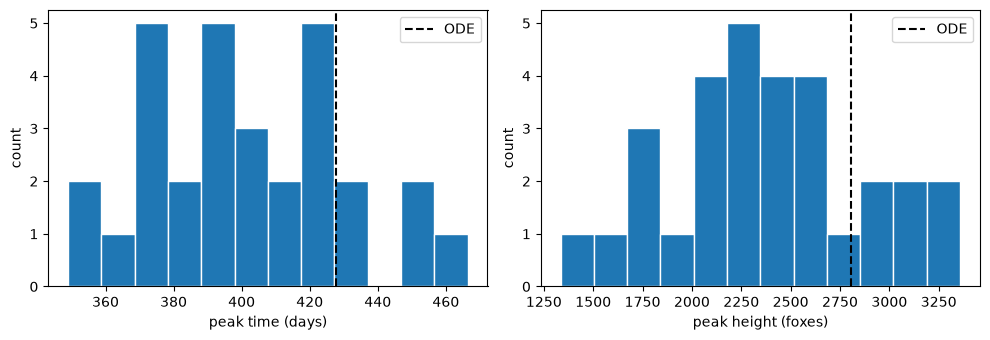

In [5]:
def second_peak(times, foxes):
    times, foxes = np.asarray(times), np.asarray(foxes)
    if len(times) != len(foxes) or len(times) == 0:
        raise ValueError('Need equally sized nonempty arrays')
    # Include the state carried into day 200, because the path is a step function.
    j = np.searchsorted(times, 200.0, side='right')-1
    if j < 0:
        raise ValueError('Trajectory must start at or before day 200')
    mask = (times > 200) & (times <= 600)
    tt = np.r_[200.0, times[mask]]
    ff = np.r_[foxes[j], foxes[mask]]
    i = int(np.argmax(ff))  # earliest occurrence resolves ties
    if ff[i] > 100 and 205 < tt[i] < 595:
        return float(tt[i]), int(ff[i])
    return None

def fox_summary(rng, mean_clock=False):
    # Same event process, but no full trajectory or post-extinction rabbit births.
    t, R, F = 0.0, R0, F0
    peak_t, peak_f = 200.0, -1
    extinction = np.nan
    events = 0
    rand = rng.random
    while t < 600 and F > 0:
        a, b, c, d = k1*R, k2*R*F, k3*R*F, k4*F
        Q = a+b+c+d
        if Q == 0:
            break
        x = (1-rand())*Q
        clock_draw = 1-rand()
        dt = 1/Q if mean_clock else -math.log(clock_draw)/Q
        new_t = t+dt
        if t <= 200 <= new_t and peak_f < 0:
            peak_t, peak_f = 200.0, F
        if new_t > 600:
            break
        if x <= a: R += 1
        elif x <= a+b: R -= 1
        elif x <= a+b+c: F += 1
        elif x <= Q: F -= 1
        else: raise RuntimeError('Invalid event')
        if R < 0 or F < 0: raise RuntimeError('Negative population')
        t = new_t
        events += 1
        if 200 < t <= 600 and F > peak_f:
            peak_t, peak_f = t, F
        if F == 0:
            extinction = t
    valid = peak_f > 100 and 205 < peak_t < 595
    return (peak_t if valid else np.nan,
            peak_f if valid else np.nan, extinction, events)

def ensemble(N, seed):
    return np.array([fox_summary(np.random.default_rng(s))
                     for s in np.random.SeedSequence(seed).spawn(N)])

def describe(data):
    peaks = data[np.isfinite(data[:,0]), :2]
    n = len(peaks)
    return dict(n=n, fraction=n/len(data), mean=peaks.mean(axis=0),
                median=np.median(peaks,axis=0),
                iqr=np.percentile(peaks,[25,75],axis=0),
                se=peaks.std(axis=0,ddof=1)/np.sqrt(n))

# Verify the summary optimization against full paths, including the time boundary.
for seed in range(10):
    ts, rs, fs = kmc(R0,F0,600,np.random.default_rng(seed))
    summary = fox_summary(np.random.default_rng(seed))
    expected = second_peak(ts,fs)
    assert (expected is None and np.isnan(summary[0])) or np.allclose(expected,summary[:2])
    deaths = ts[(fs == 0) & (ts <= 600)]
    assert (not len(deaths) and np.isnan(summary[2])) or (len(deaths) and deaths[0] == summary[2])
assert second_peak([0,210,601],[0,150,1000]) == (210.0,150)
assert second_peak([0,204,210],[0,150,140]) is None
assert second_peak([0,250,300],[0,100,0]) is None

start = time.perf_counter()
data100 = ensemble(100, 3005137)
elapsed100 = time.perf_counter()-start
stats100 = describe(data100)
print('100-run statistics:', stats100)
print(f'Timing: {elapsed100:.2f} s for 100; projected 3000: {30*elapsed100:.1f} s')
fig, axs = plt.subplots(1,2,figsize=(10,3.5))
# Find the second peak from the ODE solution after day 200
ode_mask = t_ode > 200
ode_peak_idx = np.argmax(F_ode[ode_mask])
ode_peak_time = t_ode[ode_mask][ode_peak_idx]
ode_peak_height = F_ode[ode_mask][ode_peak_idx]
for j,(label,ode_value) in enumerate(zip(['peak time (days)','peak height (foxes)'],[ode_peak_time,ode_peak_height])):
    axs[j].hist(data100[:,j][np.isfinite(data100[:,j])],bins=12,edgecolor='white')
    axs[j].axvline(ode_value,color='k',ls='--',label='ODE')
    axs[j].set(xlabel=label,ylabel='count'); axs[j].legend()
plt.tight_layout(); plt.show()

*Answer:*
In the independent 100-run sample, 30/100 (30%) have a defined second peak. Time: mean 400.7 days, median 397.3 days, IQR 377.9–421.4 days. Height: mean 2384, median 2348, IQR 2131–2628 foxes. Compare with the ODE peak at day 427.8, height 2804.
These statistics are conditional on the defined peak existing. Extinction removes some paths, random fluctuations change the timing and size of recovery, and nonlinear rates mean that ensemble averages need not satisfy the ODE: $E[RF] \ne E[R]E[F]$.
The definition is a window maximum, not a cycle counter or a test for a local maximum. It can select a later cycle, a transient spike, or a high point on an unfinished rising branch. It can also reject a real peak close to a window boundary, or below 101 foxes. Tied maxima require a convention; here the first occurrence wins. The maximum is found across the whole window before applying the boundary exclusion.

## 4. How many runs are enough?

Every number in task 3 came from random runs, so it has its own uncertainty. Repeat
task 3 with 100, 300, 1000 and 3000 trajectories. (Time it first, and work out how
long 3000 will take before you start.)

- How do the mean second-peak time and height change with the number of runs?
- Work out the **standard error** of each mean, $s / \sqrt{n}$, where $s$ is the
  standard deviation and $n$ the number of trajectories with a peak. How does it
  scale with $n$?
- Give the expected time and height of the second peak, and their interquartile
  ranges, to a precision you can justify. Say how you justified it.

In [6]:
import time

start = time.perf_counter()
data3000 = ensemble(3000, 4005137)
ensemble_elapsed = time.perf_counter() - start

print(f'3000 runs took {ensemble_elapsed:.2f} s')
print('N | peaks | fraction | mean time +/- SE | mean height +/- SE')
for N in [100, 300, 1000, 3000]:
    s = describe(data3000[:N])
    print(
        f"{N:4} | {s['n']:4} | {s['fraction']:.3f} | "
        f"{s['mean'][0]:.2f} +/- {s['se'][0]:.2f} | "
        f"{s['mean'][1]:.1f} +/- {s['se'][1]:.1f}"
    )

final_stats = describe(data3000)
print('Final conditional statistics:', final_stats)

# Fix: ensure a fresh write by using 'w' and handling potential stale handles
import os

output_filename = 'kmc_3000_output.csv'
if os.path.exists(output_filename):
    os.remove(output_filename)

np.savetxt(
    output_filename,
    data3000,
    delimiter=',',
    header='peak_time_days,peak_height_foxes,fox_extinction_day,events_before_stop',
    comments='',
)
print(f'Successfully saved to {output_filename}')

3000 runs took 157.55 s
N | peaks | fraction | mean time +/- SE | mean height +/- SE
 100 |   38 | 0.380 | 402.43 +/- 5.99 | 2642.1 +/- 148.4
 300 |  115 | 0.383 | 399.01 +/- 3.07 | 2545.1 +/- 70.7
1000 |  336 | 0.336 | 399.79 +/- 1.88 | 2428.2 +/- 36.5
3000 |  984 | 0.328 | 399.05 +/- 1.02 | 2364.5 +/- 19.6
Final conditional statistics: {'n': 984, 'fraction': 0.328, 'mean': array([ 399.05045043, 2364.54471545]), 'median': array([ 397.84923456, 2262.5       ]), 'iqr': array([[ 375.97496344, 1926.        ],
       [ 418.39617166, 2700.        ]]), 'se': array([ 1.02008367, 19.62728656])}
Successfully saved to kmc_3000_output.csv


*Answer:*
Of the 3,000 runs, 984 have a defined peak. Conditional expected peak time is approximately 399 days (SE 1.02 days), with IQR approximately 376–418 days. Conditional expected height is approximately 2360 foxes (SE 19.6), with IQR approximately 1930–2700 foxes. These rounded precisions reflect the sampling errors, not the raw number of digits printed by Python.
The means fluctuate rather than moving monotonically toward a limit. For independent trajectories of finite variance, the standard error is $s/\sqrt{n}$, so four times as many accepted peaks approximately halves the uncertainty. These SEs describe sampling error of the mean, whereas the IQR describes the variability of individual trajectories. Quartiles have their own sampling uncertainty and are reported approximately.

## 5. How likely is it that the foxes die out?

From your largest set of runs, what fraction have **no foxes left at day 600**?
That fraction $p$ estimates a probability. Its standard error is
$\sqrt{p(1-p)/N}$ for $N$ runs.

- Give the probability that the foxes die out before 600 days, with its uncertainty.
- How many runs would you need to know it to within ±1 percentage point? To within
  ±0.1?
- Plot a histogram of the times at which the foxes die out. When does it usually
  happen?

2077 / 3000 extinct; p=0.692333, SE=0.008426
+/- 1 percentage points: 2,131 runs (1 SE), 8,183 (approx 95%); worst-case 1-SE requirement 2,500
+/- 0.1 percentage points: 213,008 runs (1 SE), 818,292 (approx 95%); worst-case 1-SE requirement 250,000
Extinction time quartiles (conditional on extinction by day 600): [246.36577563 268.13041543 294.79081177]


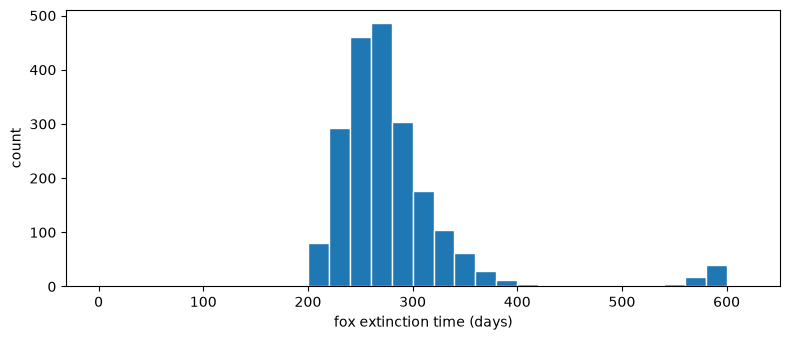

In [7]:
extinct = np.isfinite(data3000[:,2])
N = len(data3000)
p = extinct.mean()
p_se = np.sqrt(p*(1-p)/N)
print(f'{extinct.sum()} / {N} extinct; p={p:.6f}, SE={p_se:.6f}')
for eps in [.01,.001]:
    need = math.ceil(p*(1-p)/eps**2)
    need95 = math.ceil(1.96**2*p*(1-p)/eps**2)
    worst = math.ceil(.25/eps**2)
    print(f'+/- {100*eps:g} percentage points: {need:,} runs (1 SE), '
          f'{need95:,} (approx 95%); worst-case 1-SE requirement {worst:,}')
extinction_quartiles = np.percentile(data3000[extinct,2],[25,50,75])
print('Extinction time quartiles (conditional on extinction by day 600):',extinction_quartiles)
fig, ax = plt.subplots(figsize=(8,3.5))
ax.hist(data3000[extinct,2],bins=np.arange(0,621,20),edgecolor='white')
ax.set(xlabel='fox extinction time (days)',ylabel='count')
plt.tight_layout(); plt.show()

*Answer:*
The estimated probability of fox extinction by day 600 is 69.2% ± 0.8 percentage points (one SE); an approximate 95% interval is 67.6%–70.9%. Conditional extinction-time quartiles are 246, 268, 295 days, consistent with losses around the low-fox trough after the initial boom. The histogram shows whether any later losses also occur.
The requested ± accuracies are ambiguous without a confidence level. The code gives both one-standard-error and approximate 95% requirements. The plug-in estimates assume the true probability is close to the measured fraction; a conservative bound uses $p(1-p)\leq 1/4$ (2,500 and 250,000 runs for one SE; 9,604 and 960,400 for approximate 95%). The histogram includes only extinction events by day 600, with surviving paths censored.

## 6. Your project

One paragraph. Is there any part of your project where the numbers are small
enough, or the events discrete and random enough, that a continuum model (an ODE or
a PDE) could mislead you, the way the ODE does about the foxes? Think about
molecules on a surface, cells, bubbles, particles, defects, failures. If there is,
what would the "events" and their rates be? If there isn't, why is a continuum model
good enough?

*Answer:*
A project I was thinking of involves catalytic nanoparticles with only a few active surface sites. An ODE for mean coverage could predict a small positive adsorbate population even though an individual particle often has no adsorbates and cannot react until another molecule arrives. A KMC model could include adsorption at rate $k_{ads}P N_{empty}$, desorption at rate $k_{des}N_{ads}$, and surface reaction at rate $k_{rxn}N_{reactive\ pairs}$, with site occupancies updated one event at a time. This would capture fluctuations, blocked sites, and intervals with no reaction that a mean coverage model can miss.

## Stretch problems

**(a) Faster.** Time one trajectory. Then find where the time goes (`%prun`, or
time the pieces). Try Python's `random.random()` in place of `rng.random()`,
appending to lists versus filling a preallocated array, and recording only every
100th event. How much faster can you make it?

**(b) Bigger, on Explorer.** The `.py` paired with this notebook is a script.
Make a copy that runs 10,000 trajectories and saves the second-peak times and heights
and the extinction times with `np.savetxt`, and run it as a batch job on Explorer,
as in Lecture 9. Do your answers to tasks 4 and 5 hold up?

**(c) Is the random clock worth it?** Wikipedia notes that advancing the clock by
$\Delta t = 1/Q_k$ every step, instead of an exponentially distributed $\Delta t$, gives
"the same *average* time scale" (and that note is marked *citation needed*). Test it.
Make a copy of your `kmc` function that uses $\Delta t = 1/Q$, and run both versions
many times. Compare the probability that the foxes die out by day 600, the fraction of
runs with a second peak, and the mean time and height of that peak, each with its
standard error. Which differences are bigger than their uncertainty? How many runs did
you need before you could tell? (Several thousand of each; (a) and (b) help.) Why might
some quantities change and others not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.